In [1]:
# Parameters
num_cores = 8


In [2]:
import os
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={num_cores}"

# Visualize Model Output

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


-1.726604649307629 reduced X^2 of all evaluated imaging data combined (without degrees of freedom subtracted).
reduced chi^2 of data  0 =  1.7266046493076295


/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/lenstronomy/Plots/model_band_plot.py:218: RuntimeWarning: invalid value encountered in log10
  np.log10(self._data),
/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/lenstronomy/Plots/model_band_plot.py:1445: RuntimeWarning: invalid value encountered in log10
  np.log10(model),


/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/lenstronomy/Plots/model_band_plot.py:916: RuntimeWarning: invalid value encountered in log10
  source_scale = np.log10(source)


<Axes: >

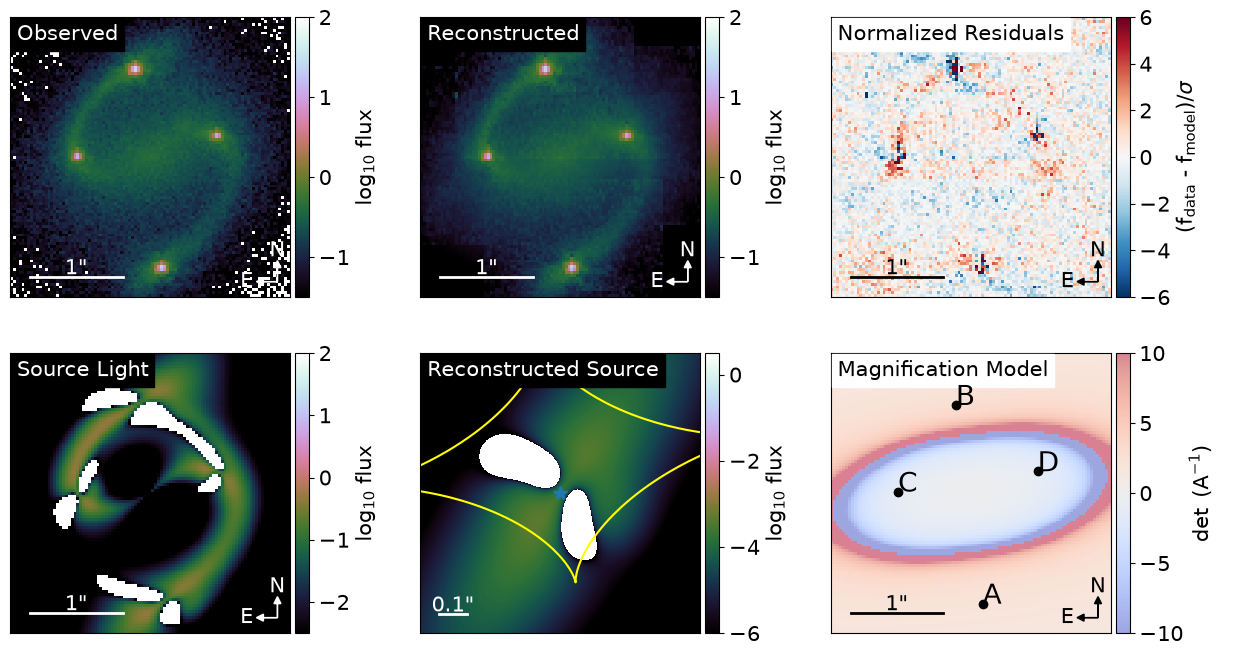

In [3]:
from dolphin.processor import Processor
from dolphin.analysis.output import Output
from dolphin.processor.config import ModelConfig
from lenstronomy.Plots.model_plot import ModelPlot
import matplotlib.pyplot as plt
import numpy as np

name='lensed_agn'
ID=f'jax'
io_dir=f"simulation"
output = Output(io_dir)

output.load_output(name, ID)

kwargs_result = output.kwargs_result
multi_band_list = output._multi_band_list_out
kwargs_data_joint = output.get_kwargs_data_joint(f"{name}")

config = ModelConfig(
            lens_name=name,
            io_directory=io_dir,
            settings=output.model_settings,
        )

mask = config.get_masks()
kwargs_model = config.get_kwargs_model()
constraints = config.get_kwargs_constraints()
likelihood = config.get_kwargs_likelihood()

modelPlot = ModelPlot(multi_band_list, kwargs_model, kwargs_result, image_likelihood_mask_list=mask)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))

axes = ax.flatten()

modelPlot.data_plot(band_index=0, ax=axes[0], vmin=-1.5, vmax=2)
modelPlot.model_plot(ax=axes[1], band_index=0, vmin=-1.5, vmax=2)
modelPlot.normalized_residual_plot(ax=axes[2],vmin=-6,vmax=6,band_index=0, cmap='RdBu_r')

modelPlot.decomposition_plot(
            ax=axes[3], 
            kwargs_title={"text": "Source Light"}, 
            source_add=True, 
            unconvolved=True, 
            vmin=-2.5,
            vmax = 2.,
            band_index=0
                )
            
modelPlot.source_plot(
            ax=axes[4], kwargs_title={"text": "Reconstructed Source"}, delta_pix_source=0.001, num_pix=1000, vmin = -6., vmax = 0.5, band_index=0
            )    

modelPlot.magnification_plot(ax=axes[5], kwargs_title={"text": "Magnification Model"}, cmap='coolwarm', band_index=0)

# Compare lens model posteriors to truth

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


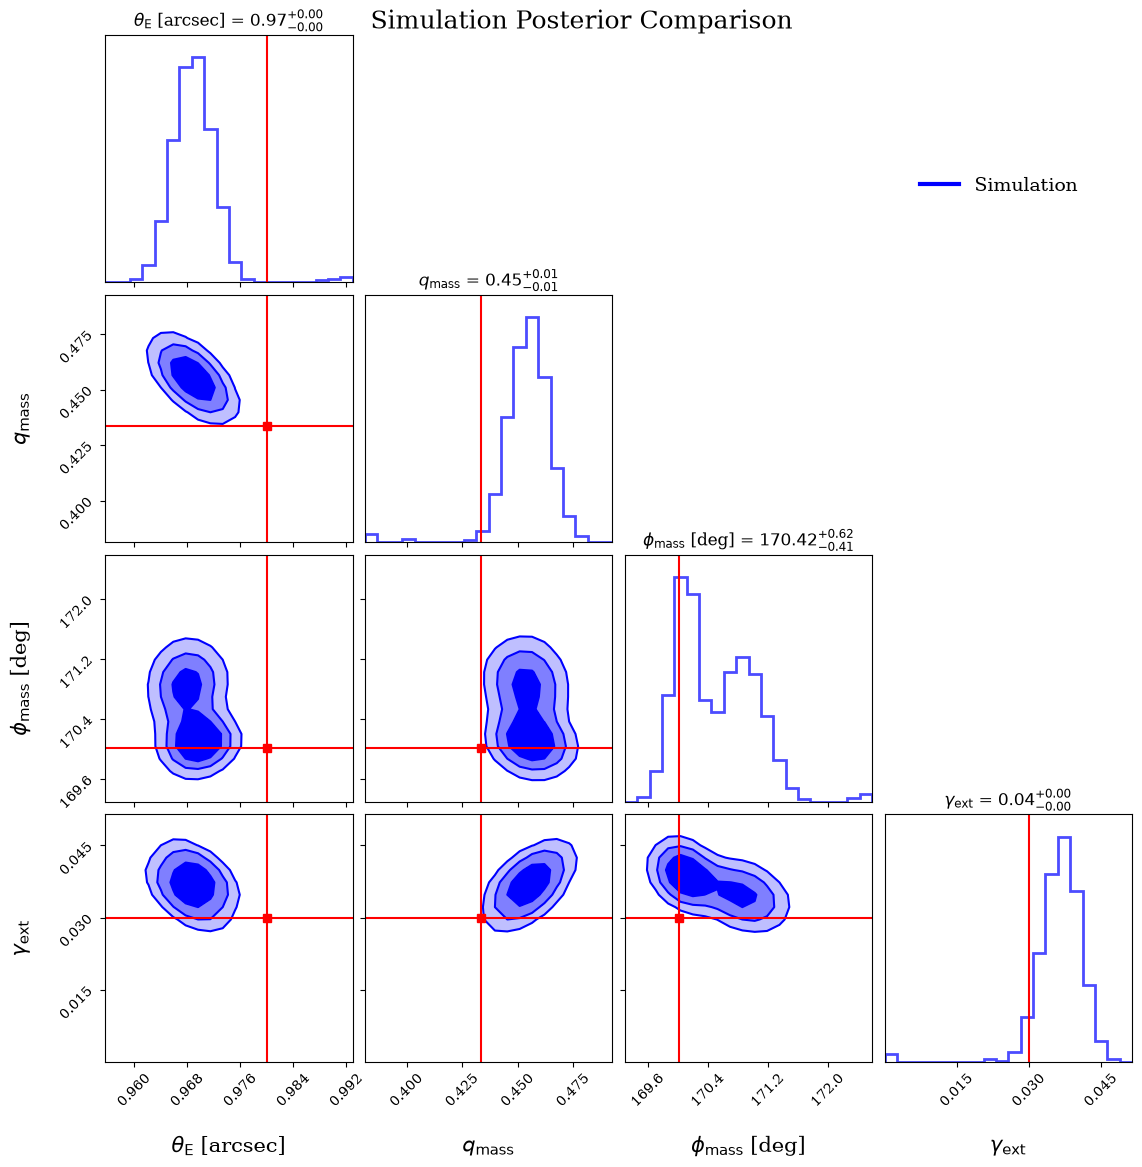

In [4]:
import corner
import matplotlib as mpl
from lenstronomy.Util import param_util

mpl.rcParams["font.family"] = "serif"

def load_chain(output, param_names, name, model_id, walker_ratio, burn_in):
    """
    Extract specific parameters from `output`
    """

    chain = output.get_reshaped_emcee_chain(
        name, model_id, walker_ratio, burn_in=burn_in
    )

    num_params = output.num_params_sampled

    if len(param_names) == 0:
        parameter_list = np.arange(num_params)
    else:
        parameter_list = []
        for i in param_names:
            if i in output.params_sampled:
                parameter_list.append(output.params_sampled.index(i))
            else:
                raise ValueError(
                    f"Parameter '{i}' not found. Available parameters: {output.params_sampled}"
                )

    # Flatten walkers x steps for each requested parameter
    raw_samples = {}
    for i in parameter_list:
        param_name = output.params_sampled[i]
        raw_samples[param_name] = chain[:, :, i].flatten()

    return raw_samples

def convert_ellipticity_to_q_phi(e1_samples, e2_samples):
    
    # Convert e1, e2 to phi, q
    phi_mass, q_mass = param_util.ellipticity2phi_q(e1_samples, e2_samples)
    phi_mass = np.degrees(phi_mass) % 180
    phi_mass = (phi_mass) % 180
    
    return phi_mass, q_mass

param_names = [
    "theta_E_lens0",
    "e1_lens0",
    "e2_lens0",
    "gamma_ext_lens1",
]

# Load chains
name = "lensed_agn"
burn_in = 0

output = Output("simulation")
output.load_output("lensed_agn", "jax")
data_dict = load_chain(output, param_names, "lensed_agn",
                          "jax", 10, burn_in)
phi_mass, q_mass = convert_ellipticity_to_q_phi(data_dict["e1_lens0"], data_dict["e2_lens0"])
data_starred = np.column_stack([
    data_dict["theta_E_lens0"],
    q_mass,
    phi_mass,
    data_dict["gamma_ext_lens1"],
])

# Labels
labels = [
    r"$\theta_{\rm E}$ [arcsec]",
    r"$q_{\rm mass}$",
    r"$\phi_{\rm mass}$ [deg]",
    r"$\gamma_{\rm ext}$",
]


true_theta_E = .98
true_e1      = 0.371517
true_e2      = -0.13498
true_gamma_ext = 0.03

# Convert the truths the same way as the samples
true_phi_mass, true_q_mass = convert_ellipticity_to_q_phi(
    np.array([true_e1]), np.array([true_e2])
)

truths = [
    true_theta_E,
    true_q_mass[0],
    true_phi_mass[0],
    true_gamma_ext,
]

bins=20
fig = corner.corner(
    data_starred,
    labels=labels,
    truths=truths,
    truth_color="red",
    color="blue",
    levels=(0.393, 0.675, 0.865),
    smooth=1.0,
    fill_contours=True,
    plot_datapoints=False,
    show_titles=True,
    hist_kwargs={
        "linewidth": 2,
        "density": True,
        "alpha": 0.7,
    },
    contour_kwargs={
        "linewidths": 1.5,
    },
    label_kwargs={
        "fontsize": 15,
    },
    title_kwargs={
        "fontsize": 12,
    },
)

handles = [
    plt.Line2D(
        [],
        [],
        color="blue",
        lw=3,
        label="Simulation",
    ),
]

for ax in fig.get_axes():
    ax.tick_params(labelsize=10)


fig.axes[0].legend(
    handles=handles,
    fontsize=14,
    frameon=False,
    bbox_to_anchor=(4.0, 0.5),
)


plt.suptitle(
    "Simulation Posterior Comparison",
    fontsize=18,
)

fig.set_size_inches(
    12,
    12,
)


#plt.savefig("posterior.png")
plt.show()

# Cosmological Inference

Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4
Loaded output for lensed_agn with model ID jax.
dolphin version used: 1.5.0
lenstronomy version used: 1.14.2
jaxtronomy version used: 0.1.4


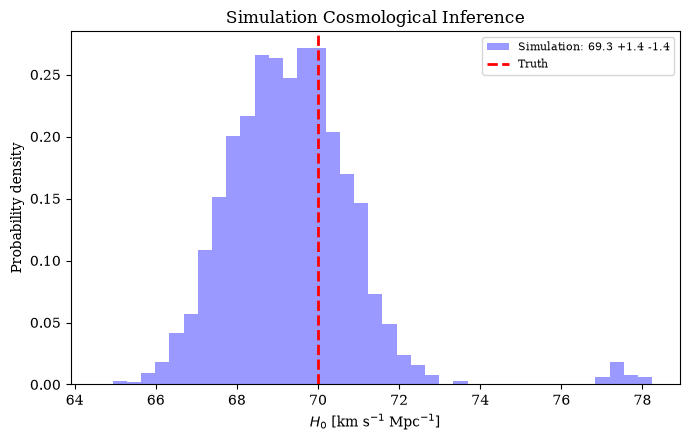

In [5]:
from astropy.cosmology import FlatLambdaCDM
from dolphin.analysis.cosmology import Cosmology

cosmo_fiducial = FlatLambdaCDM(H0=68, Om0=0.3) # same as during modeling
io_directory = "simulation"
lens_name = "lensed_agn"
model_id = "jax"
z_lens = 0.481053
z_source = 0.788751
sigma_v_observed = 270
sigma_v_observed_error = 10

burn_in = 0
n_samples = 5000
rng_seed=42
rng = np.random.default_rng(seed=rng_seed)

# approximate JWST/NIRSpec parameters
kwargs_seeing = {"psf_type": "GAUSSIAN", "fwhm": 0.14}

kwargs_aperture = {
    "aperture_type": "slit",
    "length": 0.55,
    "width": 0.55,
    "center_ra": 0.00,
    "center_dec": 0,
    "angle": 0,
}

kwargs_numerics_galkin = {
    "interpol_grid_num": 1000,
    "log_integration": True,
    "max_integrate": 1e3,
    "min_integrate": 1e-4,
}

kwargs_kin_api = {"kwargs_numerics_galkin": kwargs_numerics_galkin,
                  "sampling_number": 1000,
                  "Hernquist_approx": False,
                  "MGE_light": True,
                  "MGE_mass": False,
                  "kinematics_backend": "galkin"
                }

# simulation has no anisotropy, so probe
# small changes as an example
beta_min, beta_max = -0.03, 0.03
beta_draws = rng.uniform(
            size=n_samples,
            low=beta_min,
            high=beta_max,
        )

band_config = {
    "F115W": {
        "lens_light_indices": [0, 1],
        "source_indices": [0, 1],
        "exclude_lens_light_indices": [],
    }
}

# no kappa_ext in simulation
kappa_ext_samples = np.zeros(n_samples)

def normalize_ln_weights(ln_w):
    """Stable conversion of log-weights to normalized weights."""
    ln_w = np.asarray(ln_w, dtype=float)
    ln_w = ln_w - np.max(ln_w[np.isfinite(ln_w)])
    w = np.exp(ln_w)
    return w / np.sum(w)


def wquantile(values, weights, percentiles):
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    m = np.isfinite(v) & np.isfinite(w) & (w > 0)
    v, w = v[m], w[m]
    if v.size == 0:
        return [np.nan for _ in percentiles]
    order = np.argsort(v)
    v, w = v[order], w[order]
    cdf = np.cumsum(w) / np.sum(w)
    qs = np.asarray(percentiles, dtype=float) / 100.0
    idx = np.clip(np.searchsorted(cdf, qs, side="left"), 0, v.size - 1)
    return v[idx].tolist()


def summary_label(name, values, weights):
    p16, p50, p84 = wquantile(values, weights, [16, 50, 84])
    return f"{name}: {p50:.1f} +{p84 - p50:.1f} -{p50 - p16:.1f}"


h0_all, ln_w_nobic_all, ln_w_bic_all, labels = [], [], [], []
cosmology = Cosmology(
    io_directory=io_directory,
    lens_name=lens_name,
    model_id=model_id,
    z_lens=z_lens,
    z_source=z_source,
    cosmo_fiducial=cosmo_fiducial,
    lens_model_kinematics_bool=[True, False],
    light_model_kinematics_bool=[True, True],
    kwargs_seeing=kwargs_seeing,
    kwargs_aperture=kwargs_aperture,
    anisotropy_model="const",
    walker_ratio=10,
    burn_in=burn_in,
    n_samples=n_samples,
    rng_seed=rng_seed,
    **kwargs_kin_api
)

ddt_all = load_chain(cosmology.output, ["D_dt"], "lensed_agn", "jax", 10, 0)["D_dt"]
random_indices = rng.choice(ddt_all.size, size=n_samples, replace=False)
ddt_model = ddt_all[random_indices]

ddt_corrected = ddt_model / (1 - kappa_ext_samples)
h0_sampled, _, g_samples = cosmology.calculate_sampled_h0(ddt_corrected)

h0_sampled = h0_sampled[:, 0]

# model-predicted velocity dispersion
sigma_v_dimensionless = cosmology.velocity_dispersion_dimension_less(
                                                               beta_draws=beta_draws,
                                                               band_config=band_config,
                                                               kinematics_band="F115W"
                                                            )

ln_kin_weight = cosmology.compute_logarithmic_kinematic_likelihood(
    sigma_v_observed=sigma_v_observed,
    sigma_v_observed_error=sigma_v_observed_error,
    J_dimensionless_samples=sigma_v_dimensionless,
    kappa_ext_samples=kappa_ext_samples,
    g_samples=g_samples
)
w_flatH0 = h0_sampled / ddt_corrected

ln_w_nobic = np.log(w_flatH0) + ln_kin_weight
ln_w_bic = ln_w_nobic

h0_all.append(h0_sampled)
ln_w_nobic_all.append(ln_w_nobic)
ln_w_bic_all.append(ln_w_bic)
labels.append(np.full(len(h0_sampled), model_id))

# Weights
#   - individual: normalized within each model (BIC cancels anyway)
#   - joint: BIC weighted, normalized once across all models
w_individual = [normalize_ln_weights(lw) for lw in ln_w_nobic_all]

h0_joint = np.concatenate(h0_all)
w_joint = normalize_ln_weights(np.concatenate(ln_w_bic_all))


lo = min(np.min(h) for h in h0_all)
hi = max(np.max(h) for h in h0_all)
bins = np.linspace(lo, hi, 40)

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

ax.hist(
    h0_all,
    bins=bins,
    weights=w_individual,
    density=True,
    color="blue",
    alpha=0.4,
    label=summary_label("Simulation", h0_all, w_individual),
)


ax.axvline(x=70, color='r', linestyle='--', linewidth=2, label='Truth')

ax.set_xlabel(r"$H_0$ [km s$^{-1}$ Mpc$^{-1}$]")
ax.set_ylabel("Probability density")
ax.set_title("Simulation Cosmological Inference")
ax.legend(fontsize=8)
fig.tight_layout()
#fig.savefig(f"{lens_name}_H0_joint.png", dpi=200)
plt.show()